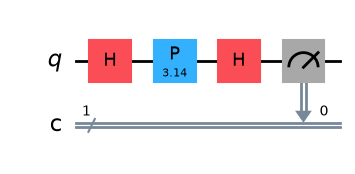

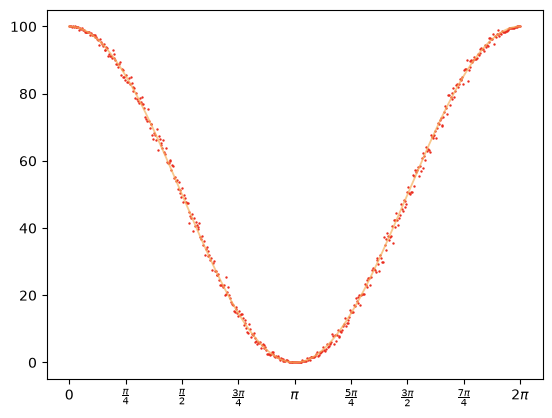

<Figure size 1920x1440 with 0 Axes>

In [ ]:
"""
Simulazione di un esperimento di interferenza quantistica su singolo qubit.

Il circuito dimostra come una fase quantistica diventi misurabile solo attraverso l'interferenza:
1. Prima porta H: crea una sovrapposizione bilanciata degli stati |0> e |1>.
2. Porta Phase (P): applica uno sfasamento 'theta'. In questo istante, la fase non ha alcun effetto misurabile (le probabilità di misurazione restano esattamente 50/50).
3. Seconda porta H: fa interferire gli stati. Solo ora lo sfasamento si converte in una differenza di ampiezza, rendendo l'effetto della fase effettivamente misurabile.
4. Misurazione: rileva lo stato finale.

Il codice esegue questa sequenza per 500 valori di theta (da 0 a 2π), calcolando (per ciascun angolo) la probabilità di ottenere '0' su 1000 misurazioni. 
Infine, genera un grafico che mostra questa probabilità in funzione di theta, confrontando i dati simulati con la curva teorica P(0) = cos²(theta/2).
"""


import math
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_bloch_multivector, 
    plot_state_qsphere,
    circuit_drawer, 
    plot_histogram
)

#Creazione dell'Ambiente di Simulazione
simulator = AerSimulator()

#Creazione Liste per Rappresentazione Grafica dei Risultati
N=[]
In= []

#Creazione di una variabile per rappresentare il circuito a metà del ciclo for
a = 0 

#Definizione Circuito
for i in np.linspace(0, 2*np.pi, 500):
    a = a + 1
    In.append(i)
    qc = QuantumCircuit(1,1)
    qc.h(0)
    qc.p(qubit=0, theta= i)
    qc.h(0)
    qc.measure(0,0)
    job = simulator.run(qc, shots= 1000)
    result= job.result()
    counts = result.get_counts()
    n_0 = counts.get('0', 0)/10
    N.append(n_0)
    if a == 250:
        c = qc. draw("mpl")
        display(c)

#Rappresentazione Grafica dei Risultati
plt.scatter(In, N, color= "#EA2A1C", s=0.5)

#Rappresentazione Curva Teorica
shots_list = np.linspace(0, 2*np.pi, 1000)
curva_teorica = ((np.cos(shots_list/2))**2)*100
plt.plot(shots_list, curva_teorica, linewidth = 1.3, color="#F6B15D", alpha =0.7 )

# Etichette Pi, Asse X
posizioni = [
    0, 
    np.pi/4, 
    np.pi/2, 
    3*np.pi/4, 
    np.pi, 
    5*np.pi/4, 
    3*np.pi/2, 
    7*np.pi/4, 
    2*np.pi
]
etichette = [
    '0', 
    r'$\frac{\pi}{4}$', 
    r'$\frac{\pi}{2}$', 
    r'$\frac{3\pi}{4}$', 
    r'$\pi$', 
    r'$\frac{5\pi}{4}$', 
    r'$\frac{3\pi}{2}$', 
    r'$\frac{7\pi}{4}$', 
    r'$2\pi$'
]
plt.xticks(posizioni, etichette)

#Risolulzione Grafico
plt.figure(dpi=300)

plt.show()
